# Lab 11: Data Interpolation and Splines

**Interpolation** constructs a function that passes **exactly** through all given data points:
$$p(x_i) = y_i \quad \text{for all } i = 0, 1, \ldots, n$$

Unlike regression (which *smooths* noisy data), interpolation is used when data points are **known exactly** (e.g., tabulated engineering values, experimental measurements at specific conditions).

## Learning Objectives

By the end of this session, you will be able to:
- Explain the difference between **interpolation** and **regression**
- Build **Newton's divided-difference** table and evaluate the interpolating polynomial
- Implement **Lagrange interpolation** using basis polynomials
- Identify **Runge's phenomenon** and explain why high-degree polynomials can fail
- Construct **quadratic splines** by setting up and solving a linear system
- Derive the **cubic spline** equations (natural and not-a-knot boundary conditions)
- Use `scipy.interpolate.CubicSpline` for practical engineering problems

## Session Outline

| # | Topic |  
|---|-------| 
| 1 | Introduction: Why Interpolation? |  
| 2 | Newton's Divided Differences |  
| 3 | Lagrange Interpolation |  
| 4 | Runge's Phenomenon |  
| 5 | Quadratic Splines |  
| 6 | Cubic Splines |  
| 7 | `scipy.interpolate.CubicSpline` |  

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, interp1d

---
## 1. Introduction: Why Interpolation?

### 1.1 Interpolation vs. Regression

| Feature | Interpolation | Regression |
|---------|--------------|------------|
| Passes through data points? | **Yes** (exactly) | No (minimizes error) |
| Handles noisy data? | Poorly | Well |
| Number of parameters | = number of data points | Fewer than data |
| Use case | Exact tabulated data | Noisy measurements |

### 1.2 Running Datasets

We will use these datasets throughout the lab:

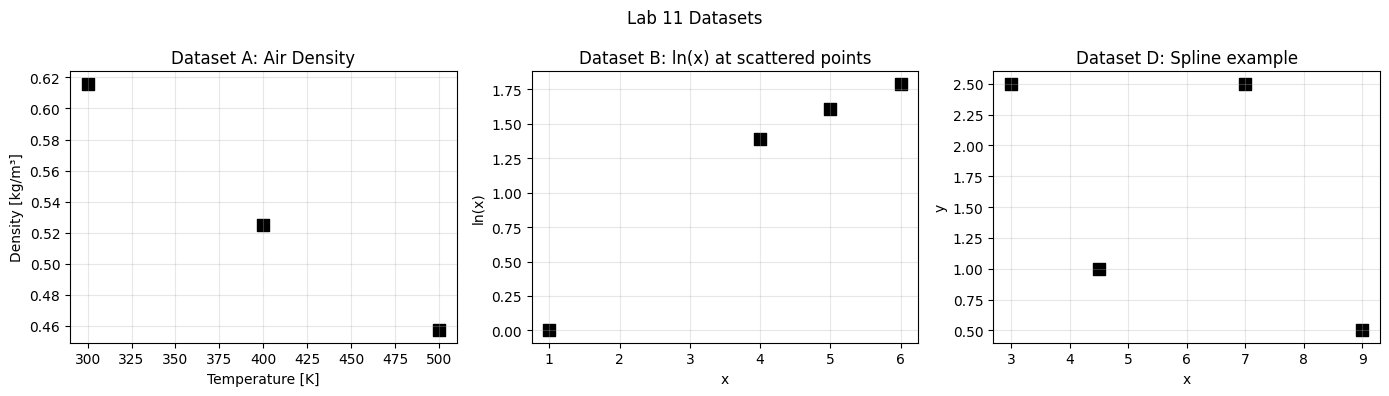

In [2]:
# Dataset A: Air density vs. temperature (from textbook Table 17.1)
T_air  = np.array([300., 400., 500.])        # temperature [K]
rho_air = np.array([0.616, 0.525, 0.457])   # density [kg/m^3]

# Dataset B: Natural logarithm at scattered points
x_log  = np.array([1., 4., 6., 5.])
y_log  = np.log(x_log)

# Dataset C: Oscillating data to demonstrate Runge's phenomenon
f_runge = lambda x: 1.0 / (1.0 + 25.0 * x**2)

# Dataset D: Spline example (textbook Ex. 18.2)
x_sp = np.array([3., 4.5, 7.0, 9.0])
y_sp = np.array([2.5, 1.0, 2.5, 0.5])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(T_air, rho_air, c='k', marker='s', s=80)
axes[0].set(xlabel='Temperature [K]', ylabel='Density [kg/m³]',
            title='Dataset A: Air Density')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(x_log, y_log, c='k', marker='s', s=80)
axes[1].set(xlabel='x', ylabel='ln(x)', title='Dataset B: ln(x) at scattered points')
axes[1].grid(True, alpha=0.3)

xx = np.linspace(-1, 1, 200)
axes[2].scatter(x_sp, y_sp, c='k', marker='s', s=80)
axes[2].set(xlabel='x', ylabel='y', title='Dataset D: Spline example')
axes[2].grid(True, alpha=0.3)

plt.suptitle('Lab 11 Datasets', fontsize=12)
plt.tight_layout(); plt.show()

---
## 2. Newton's Divided Differences

### 2.1 The Idea

Newton's method builds the interpolating polynomial **incrementally**. Given $n+1$ points, the polynomial is:
$$p_n(x) = f[x_0] + f[x_0,x_1](x-x_0) + f[x_0,x_1,x_2](x-x_0)(x-x_1) + \cdots$$

### 2.2 Divided-Difference Table

The **divided differences** $f[\cdot]$ are computed recursively:

| Order | Formula | Symbol |
|-------|---------|--------|
| 0th | $f[x_i] = f(x_i)$ | $b_0^{(i)}$ |
| 1st | $f[x_i, x_{i+1}] = \dfrac{f[x_{i+1}] - f[x_i]}{x_{i+1} - x_i}$ | $b_1^{(i)}$ |
| $k$th | $f[x_i,\ldots,x_{i+k}] = \dfrac{f[x_{i+1},\ldots,x_{i+k}] - f[x_i,\ldots,x_{i+k-1}]}{x_{i+k} - x_i}$ | $b_k^{(i)}$ |

The polynomial coefficients are the **top row** of the divided-difference table:
$$b_0 = f[x_0], \quad b_1 = f[x_0,x_1], \quad b_2 = f[x_0,x_1,x_2], \quad \ldots$$

### 2.3 Example: Air Density (3 points → degree-2 polynomial)

Dataset A has 3 points: $(300, 0.616)$, $(400, 0.525)$, $(500, 0.457)$.

In [3]:
# Build the divided-difference table manually for Dataset A
x = T_air
y = rho_air

# 1st divided differences: (y[i+1] - y[i]) / (x[i+1] - x[i])
dd1 = (y[1:] - y[:-1]) / (x[1:] - x[:-1])
print('1st divided differences:', dd1)

# 2nd divided differences: (dd1[i+1] - dd1[i]) / (x[i+2] - x[i])
dd2 = (dd1[1:] - dd1[:-1]) / (x[2:] - x[:-2])
print('2nd divided differences:', dd2)

# Polynomial coefficients (top-row values)
b0 = y[0]    # = f[x0]
b1 = dd1[0]  # = f[x0, x1]
b2 = dd2[0]  # = f[x0, x1, x2]

print(f'\nb0 = {b0:.6f}')
print(f'b1 = {b1:.6f}')
print(f'b2 = {b2:.6f}')

# Evaluate at T = 350 K
x0, x1 = x[0], x[1]
T_query = 350.
rho_interp = b0 + b1*(T_query - x0) + b2*(T_query - x0)*(T_query - x1)
print(f'\nInterpolated density at T={T_query} K: {rho_interp:.5f} kg/m³')

1st divided differences: [-0.00091 -0.00068]
2nd divided differences: [1.15e-06]

b0 = 0.616000
b1 = -0.000910
b2 = 0.000001

Interpolated density at T=350.0 K: 0.56763 kg/m³


### 2.4 General Implementation

In [4]:
def newtdd_table(x, y):
    """
    Build the divided-difference table.

    Parameters
    ----------
    x, y : array-like of length n+1

    Returns
    -------
    b : 2D array of shape (n+1, n+1)
        b[0, :] contains the coefficients of Newton's polynomial
        b[:, 0] = y (zeroth-order divided differences)
    """
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    n = len(x)
    b = np.zeros((n, n))
    b[:, 0] = y                        # zeroth-order column = y values

    for j in range(1, n):              # column index (order)
        for i in range(n - j):        # row index
            b[i, j] = (b[i+1, j-1] - b[i, j-1]) / (x[i+j] - x[i])
    return b


def newtdd_eval(x, b, xx):
    """
    Evaluate Newton's interpolating polynomial at point(s) xx.

    Parameters
    ----------
    x  : array of interpolation nodes
    b  : divided-difference table (from newtdd_table)
    xx : scalar or array — evaluation point(s)

    Returns
    -------
    yy : interpolated value(s) at xx
    """
    x  = np.array(x, dtype=float)
    n  = len(x)
    xx = np.atleast_1d(np.array(xx, dtype=float))
    yy = np.full(xx.shape, b[0, 0])   # start with b0

    for j in range(1, n):
        term = b[0, j]                 # coefficient b_j
        for k in range(j):
            term = term * (xx - x[k])
        yy = yy + term

    return yy if yy.size > 1 else yy[0]

<!-- SOLUTION
b[i, j] = (b[i+1, j-1] - b[i, j-1]) / (x[i+j] - x[i])
term     = term * (xx - x[k])
-->

Divided-difference table (Dataset A):
[[ 6.16e-01 -9.10e-04  1.15e-06]
 [ 5.25e-01 -6.80e-04  0.00e+00]
 [ 4.57e-01  0.00e+00  0.00e+00]]

Coefficients: b0=0.616000, b1=-0.000910, b2=1.150000e-06

Interpolated rho at 350 K = 0.56763 kg/m³


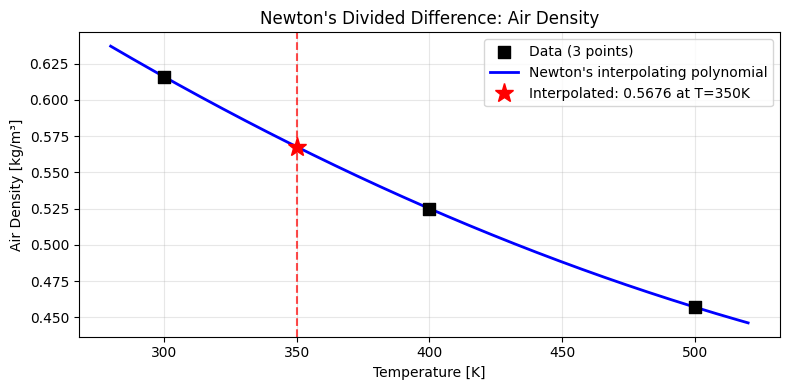

In [5]:
# Test on Dataset A
b_air = newtdd_table(T_air, rho_air)
print('Divided-difference table (Dataset A):')
print(b_air)
print(f'\nCoefficients: b0={b_air[0,0]:.6f}, b1={b_air[0,1]:.6f}, b2={b_air[0,2]:.6e}')

rho_350 = newtdd_eval(T_air, b_air, 350.)
print(f'\nInterpolated rho at 350 K = {rho_350:.5f} kg/m³')

# Plot the interpolating polynomial
T_plot = np.linspace(280, 520, 200)
rho_plot = newtdd_eval(T_air, b_air, T_plot)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(T_air, rho_air, c='k', marker='s', s=80, zorder=5, label='Data (3 points)')
ax.plot(T_plot, rho_plot, 'b-', lw=2, label="Newton's interpolating polynomial")
ax.axvline(350, color='r', ls='--', alpha=0.7)
ax.plot(350, rho_350, 'r*', ms=14, label=f'Interpolated: {rho_350:.4f} at T=350K')
ax.set(xlabel='Temperature [K]', ylabel='Air Density [kg/m³]',
       title="Newton's Divided Difference: Air Density")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### 2.5 Dataset B: ln(x) at scattered points

Newton's method works even with **unequally spaced** and **unsorted** nodes.

Divided-difference table (Dataset B — ln(x)):
[[ 0.          0.46209812 -0.05187311  0.00786553]
 [ 1.38629436  0.20273255 -0.020411    0.        ]
 [ 1.79175947  0.18232156  0.          0.        ]
 [ 1.60943791  0.          0.          0.        ]]

Approximated ln(2) = 0.628769
True        ln(2) = 0.693147
Error              = 9.2879 %


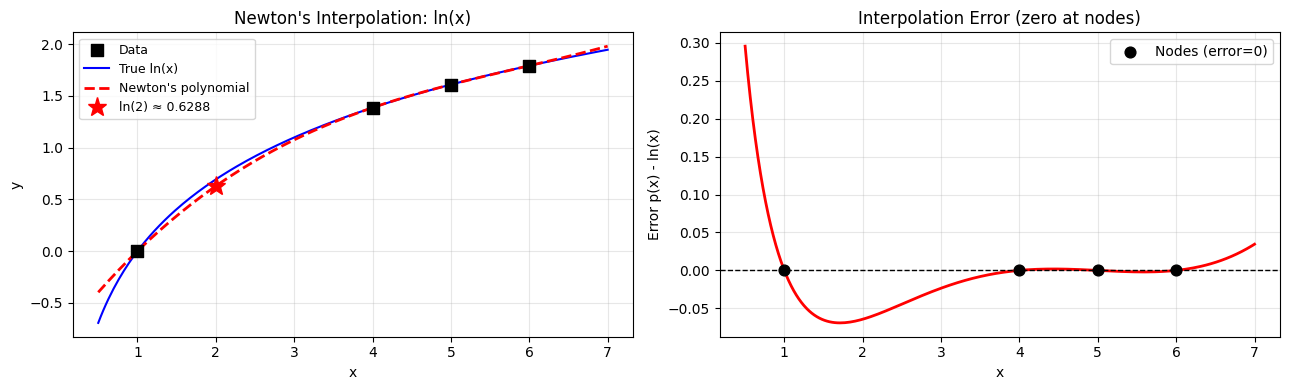

In [6]:
b_log = newtdd_table(x_log, y_log)
print('Divided-difference table (Dataset B — ln(x)):')
print(b_log)

ln2_approx = newtdd_eval(x_log, b_log, 2.)
ln2_true   = np.log(2)
err_pct    = abs(ln2_approx - ln2_true) / abs(ln2_true) * 100
print(f'\nApproximated ln(2) = {ln2_approx:.6f}')
print(f'True        ln(2) = {ln2_true:.6f}')
print(f'Error              = {err_pct:.4f} %')

x_plot = np.linspace(0.5, 7.0, 200)
y_interp = newtdd_eval(x_log, b_log, x_plot)
y_true   = np.log(x_plot)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.scatter(x_log, y_log, c='k', marker='s', s=80, zorder=5, label='Data')
ax.plot(x_plot, y_true,   'b-',  lw=1.5, label='True ln(x)')
ax.plot(x_plot, y_interp, 'r--', lw=2,   label="Newton's polynomial")
ax.plot(2, ln2_approx, 'r*', ms=14, label=f'ln(2) ≈ {ln2_approx:.4f}')
ax.set(xlabel='x', ylabel='y', title="Newton's Interpolation: ln(x)")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(x_plot, y_interp - y_true, 'r-', lw=2)
ax.axhline(0, color='k', lw=1, ls='--')
ax.scatter(x_log, np.zeros(len(x_log)), c='k', s=60, zorder=5, label='Nodes (error=0)')
ax.set(xlabel='x', ylabel='Error p(x) - ln(x)',
       title='Interpolation Error (zero at nodes)')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

**Exercise 2.1:** The viscosity of air at several temperatures is given below.

| T [°C] | 0 | 20 | 40 | 60 |
|--------|---|----|----|----|
| μ [μPa·s] | 17.2 | 18.1 | 19.1 | 19.9 |

1. Build the divided-difference table using `newtdd_table`.
2. Interpolate the viscosity at $T = 30°C$ and $T = 50°C$.
3. Plot the interpolating polynomial from 0 to 60°C.

Divided-difference table (air viscosity):
[[ 1.72e+01  4.50e-02  1.25e-04 -6.25e-06]
 [ 1.81e+01  5.00e-02 -2.50e-04  0.00e+00]
 [ 1.91e+01  4.00e-02  0.00e+00  0.00e+00]
 [ 1.99e+01  0.00e+00  0.00e+00  0.00e+00]]

Newton coefficients: b0=17.200000, b1=0.045000, b2=1.250000e-04, b3=-6.250000e-06

μ(30°C) ≈ 18.6063 μPa·s
μ(50°C) ≈ 19.5437 μPa·s


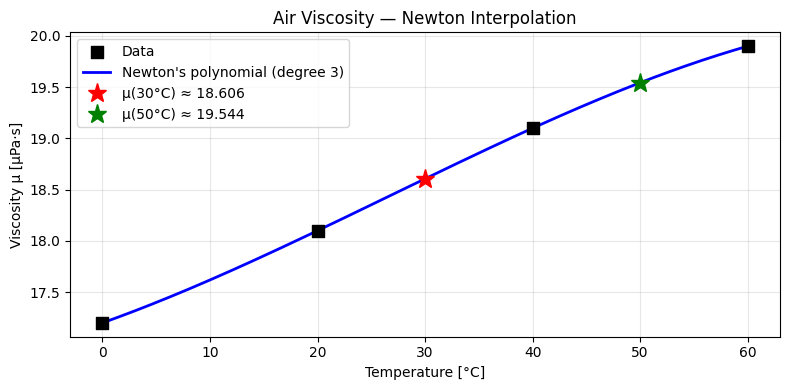

In [7]:
# --- YOUR CODE HERE ---
T_visc  = np.array([0., 20., 40., 60.])
mu_visc = np.array([17.2, 18.1, 19.1, 19.9])

# 1. Build the divided-difference table
b_visc = newtdd_table(T_visc, mu_visc)
print('Divided-difference table (air viscosity):')
print(b_visc)
print(f'\nNewton coefficients: b0={b_visc[0,0]:.6f}, b1={b_visc[0,1]:.6f}, '
      f'b2={b_visc[0,2]:.6e}, b3={b_visc[0,3]:.6e}')

# 2. Interpolate at T = 30°C and T = 50°C
mu_30 = newtdd_eval(T_visc, b_visc, 30.)
mu_50 = newtdd_eval(T_visc, b_visc, 50.)
print(f'\nμ(30°C) ≈ {mu_30:.4f} μPa·s')
print(f'μ(50°C) ≈ {mu_50:.4f} μPa·s')

# 3. Plot the interpolating polynomial from 0 to 60°C
T_plot  = np.linspace(0, 60, 200)
mu_plot = newtdd_eval(T_visc, b_visc, T_plot)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(T_visc, mu_visc, c='k', marker='s', s=80, zorder=5, label='Data')
ax.plot(T_plot, mu_plot, 'b-', lw=2, label="Newton's polynomial (degree 3)")
ax.plot(30, mu_30, 'r*', ms=14, label=f'μ(30°C) ≈ {mu_30:.3f}')
ax.plot(50, mu_50, 'g*', ms=14, label=f'μ(50°C) ≈ {mu_50:.3f}')
ax.set(xlabel='Temperature [°C]', ylabel='Viscosity μ [μPa·s]',
       title='Air Viscosity — Newton Interpolation')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 3. Lagrange Interpolation

### 3.1 Theory

Lagrange's form writes the polynomial directly in terms of **basis polynomials** $L_i(x)$:
$$p_n(x) = \sum_{i=0}^{n} y_i \, L_i(x)$$

where each basis polynomial satisfies $L_i(x_j) = \delta_{ij}$ (equals 1 at its own node, 0 at all others):
$$L_i(x) = \prod_{\substack{j=0 \\ j \neq i}}^{n} \frac{x - x_j}{x_i - x_j}$$

### 3.2 Comparison with Newton

| Feature | Newton | Lagrange |
|---------|--------|----------|
| Add a new data point? | Easy (one new column) | Must recompute all |
| Conceptual clarity | Divided differences | Basis functions |
| Result | **Identical polynomial** | **Identical polynomial** |

> Both methods produce the **unique** polynomial of degree $\leq n$ passing through $n+1$ points.

<!-- Li = Li * (xx - x[j]) / (x[i] - x[j]) # Lagrange basis -->

In [ ]:
def lagrange_basis(x, i, xx):
    """
    Evaluate the i-th Lagrange basis polynomial at xx.

    Parameters
    ----------
    x  : array of interpolation nodes
    i  : int — which basis polynomial
    xx : scalar or array — evaluation point(s)

    Returns
    -------
    Li : value(s) of L_i(xx)
    """
    x  = np.array(x, dtype=float)
    xx = np.atleast_1d(np.array(xx, dtype=float))
    n  = len(x)
    Li = np.ones(xx.shape)

    for j in range(n):
        if j != i:
            # - - - - - - - COMPLETE - - - - - - - 
            Li = Li * (xx - x[j]) / (x[i] - x[j])   # Lagrange basis
            # - - - - - - - COMPLETE - - - - - - - 
    return Li


def lagrange_interp(x, y, xx):
    """
    Evaluate the Lagrange interpolating polynomial at xx.

    Parameters
    ----------
    x, y : array — interpolation nodes and values
    xx   : scalar or array — evaluation point(s)

    Returns
    -------
    yy : interpolated value(s)
    """
    x  = np.array(x, dtype=float)
    y  = np.array(y, dtype=float)
    xx = np.atleast_1d(np.array(xx, dtype=float))
    n  = len(x)
    yy = np.zeros(xx.shape)

    for i in range(n):
        yy = yy + y[i] * lagrange_basis(x, i, xx)
    return yy if yy.size > 1 else yy[0]

<!-- SOLUTION
Li = Li * (xx - x[j]) / (x[i] - x[j])
yy = yy + y[i] * lagrange_basis(x, i, xx)
-->

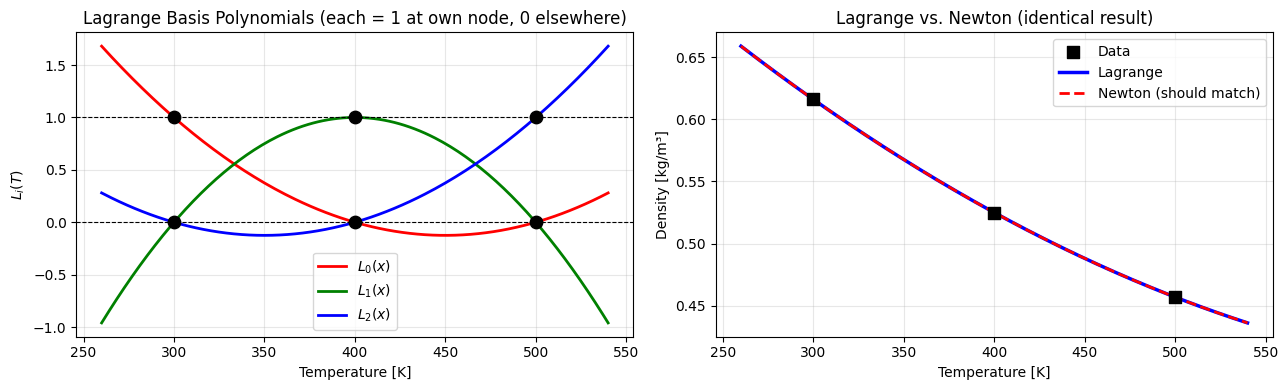

Lagrange at 350 K = 0.56762500
Newton   at 350 K = 0.56762500
Difference        = 0.00e+00  (should be ~machine precision)


In [9]:
# Visualize the Lagrange basis functions for Dataset A (3 nodes)
T_plot = np.linspace(260, 540, 200)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
colors = ['red', 'green', 'blue']
for i in range(3):
    Li_vals = lagrange_basis(T_air, i, T_plot)
    ax.plot(T_plot, Li_vals, color=colors[i], lw=2, label=f'$L_{i}(x)$')
ax.scatter(T_air, np.ones(3), c='k', s=80, zorder=5)
ax.scatter(T_air, np.zeros(3), c='k', s=80, zorder=5)
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.axhline(1, color='k', lw=0.8, ls='--')
ax.set(xlabel='Temperature [K]', ylabel='$L_i(T)$',
       title='Lagrange Basis Polynomials (each = 1 at own node, 0 elsewhere)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
rho_lagrange = lagrange_interp(T_air, rho_air, T_plot)
rho_newton   = newtdd_eval(T_air, b_air, T_plot)
ax.scatter(T_air, rho_air, c='k', marker='s', s=80, zorder=5, label='Data')
ax.plot(T_plot, rho_lagrange, 'b-', lw=2.5, label='Lagrange')
ax.plot(T_plot, rho_newton,   'r--', lw=2,   label="Newton (should match)")
ax.set(xlabel='Temperature [K]', ylabel='Density [kg/m³]',
       title='Lagrange vs. Newton (identical result)')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

rho_L = lagrange_interp(T_air, rho_air, 350.)
rho_N = newtdd_eval(T_air, b_air, 350.)
print(f'Lagrange at 350 K = {rho_L:.8f}')
print(f'Newton   at 350 K = {rho_N:.8f}')
print(f'Difference        = {abs(rho_L - rho_N):.2e}  (should be ~machine precision)')

**Exercise 3.1:** Use `lagrange_interp` to interpolate air density at four temperatures:

| T [K] | 300 | 400 | 500 | 600 |
|-------|-----|-----|-----|-----|
| ρ [kg/m³] | 0.616 | 0.525 | 0.457 | 0.404 |

1. Interpolate at $T = 350$ K, $T = 450$ K, and $T = 550$ K.
2. Plot the 3rd-degree polynomial over the range [280, 620] K.
3. Comment: why is extrapolation outside $[300, 600]$ K risky?

ρ(350 K) ≈ 0.56712 kg/m³
ρ(450 K) ≈ 0.48863 kg/m³
ρ(550 K) ≈ 0.42912 kg/m³


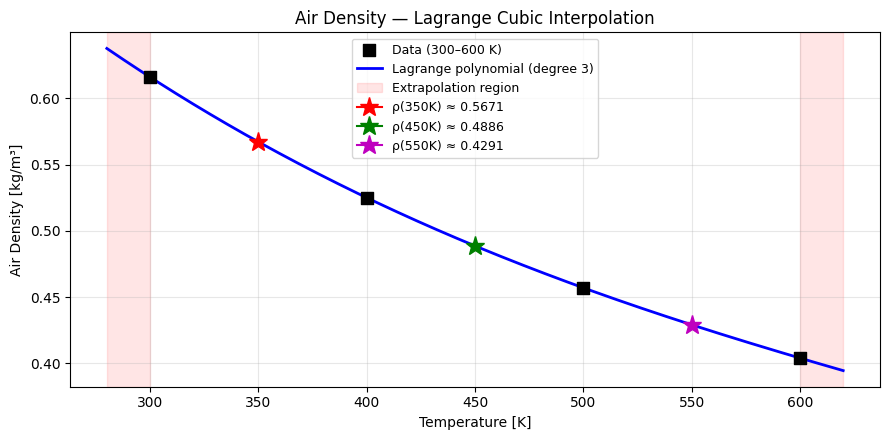


Why is extrapolation outside [300, 600] K risky?
 - The Lagrange polynomial is fitted ONLY on the 4 data points in [300, 600] K.
 - Outside that range, the cubic polynomial is unconstrained and its tails grow
   (or shrink) much faster than the true physical behavior of air density.
 - Density follows ρ ∝ 1/T (ideal gas at fixed pressure) — a nonlinear curve
   that the polynomial cannot match outside the fitting interval.
 - Small errors at the endpoints get amplified rapidly as we move away,
   so extrapolated values can be physically meaningless (even negative).



In [10]:
# --- YOUR CODE HERE ---
T4   = np.array([300., 400., 500., 600.])
rho4 = np.array([0.616, 0.525, 0.457, 0.404])

# 1. Interpolate at T = 350, 450, 550 K
for Tq in [350., 450., 550.]:
    rhoq = lagrange_interp(T4, rho4, Tq)
    print(f'ρ({Tq:.0f} K) ≈ {rhoq:.5f} kg/m³')

# 2. Plot the cubic Lagrange polynomial over [280, 620] K
T_plot   = np.linspace(280, 620, 300)
rho_plot = lagrange_interp(T4, rho4, T_plot)

# Mark the data range to highlight the extrapolation regions
mask_extrap = (T_plot < 300.) | (T_plot > 600.)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(T4, rho4, c='k', marker='s', s=80, zorder=5, label='Data (300–600 K)')
ax.plot(T_plot, rho_plot, 'b-', lw=2, label='Lagrange polynomial (degree 3)')
# shade extrapolation regions
ax.axvspan(280, 300, color='red', alpha=0.10, label='Extrapolation region')
ax.axvspan(600, 620, color='red', alpha=0.10)
for Tq, color in zip([350., 450., 550.], ['r', 'g', 'm']):
    rhoq = lagrange_interp(T4, rho4, Tq)
    ax.plot(Tq, rhoq, marker='*', ms=14, color=color,
            label=f'ρ({Tq:.0f}K) ≈ {rhoq:.4f}')
ax.set(xlabel='Temperature [K]', ylabel='Air Density [kg/m³]',
       title='Air Density — Lagrange Cubic Interpolation')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# 3. Comment on extrapolation risk
print("""
Why is extrapolation outside [300, 600] K risky?
 - The Lagrange polynomial is fitted ONLY on the 4 data points in [300, 600] K.
 - Outside that range, the cubic polynomial is unconstrained and its tails grow
   (or shrink) much faster than the true physical behavior of air density.
 - Density follows ρ ∝ 1/T (ideal gas at fixed pressure) — a nonlinear curve
   that the polynomial cannot match outside the fitting interval.
 - Small errors at the endpoints get amplified rapidly as we move away,
   so extrapolated values can be physically meaningless (even negative).
""")

---
## 4. Runge's Phenomenon

### 4.1 The Problem

**Runge's phenomenon**: using a single high-degree polynomial to interpolate at **equally spaced** nodes can produce **large oscillations** near the edges of the interval — even when the underlying function is smooth.

The canonical example is the Runge function:
$$f(x) = \frac{1}{1 + 25x^2}, \quad x \in [-1, 1]$$

### 4.2 Demonstration

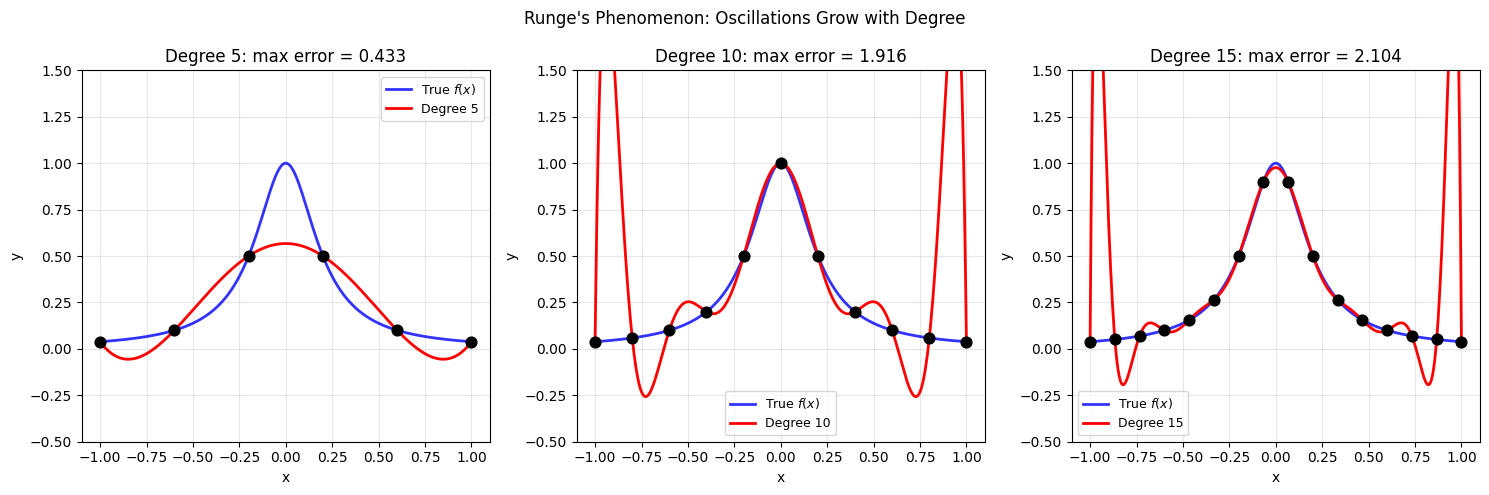

Lesson: High-degree polynomials at equally spaced nodes can FAIL near the endpoints!


In [11]:
x_dense = np.linspace(-1, 1, 400)
y_true  = f_runge(x_dense)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
degrees_demo = [5, 10, 15]

for ax, n_pts in zip(axes, degrees_demo):
    x_nodes = np.linspace(-1, 1, n_pts + 1)   # n_pts+1 equally spaced nodes
    y_nodes = f_runge(x_nodes)

    b_runge = newtdd_table(x_nodes, y_nodes)
    y_interp = newtdd_eval(x_nodes, b_runge, x_dense)

    max_err = np.max(np.abs(y_interp - y_true))

    ax.plot(x_dense, y_true,   'b-', lw=2, label='True $f(x)$', alpha=0.8)
    ax.plot(x_dense, y_interp, 'r-', lw=2, label=f'Degree {n_pts}')
    ax.scatter(x_nodes, y_nodes, c='k', s=60, zorder=5)
    ax.set(xlabel='x', ylabel='y',
           title=f'Degree {n_pts}: max error = {max_err:.3f}',
           ylim=[-0.5, 1.5])
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.suptitle("Runge's Phenomenon: Oscillations Grow with Degree", fontsize=12)
plt.tight_layout(); plt.show()
print('Lesson: High-degree polynomials at equally spaced nodes can FAIL near the endpoints!')

### 4.3 Solutions

Two main remedies exist:

| Remedy | Strategy | Advantage |
|--------|----------|-----------|
| **Chebyshev nodes** | Use $x_k = \cos\!\left(\frac{(2k+1)\pi}{2(n+1)}\right)$ | Minimizes max interpolation error |
| **Piecewise splines** | Use low-degree polynomials on each sub-interval | Smooth, no oscillations, local control |

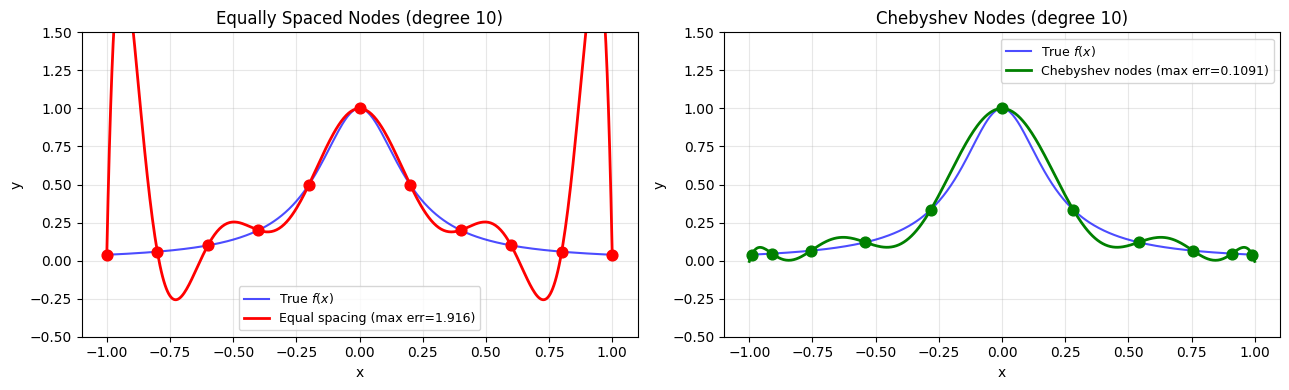

Equal spacing max error : 1.9156
Chebyshev nodes max error: 0.1091
Improvement factor: 17.6x


In [12]:
# Compare equally spaced nodes vs. Chebyshev nodes (degree 10)
n_cheb = 10

# Equally spaced
x_eq = np.linspace(-1, 1, n_cheb + 1)
y_eq = f_runge(x_eq)
b_eq = newtdd_table(x_eq, y_eq)
y_poly_eq = newtdd_eval(x_eq, b_eq, x_dense)

# Chebyshev nodes: x_k = cos((2k+1)*pi / (2*(n+1))) for k = 0..n
k = np.arange(n_cheb + 1)
x_cheb = np.cos((2*k + 1) * np.pi / (2*(n_cheb + 1)))
y_cheb = f_runge(x_cheb)
b_cheb = newtdd_table(x_cheb, y_cheb)
y_poly_cheb = newtdd_eval(x_cheb, b_cheb, x_dense)

err_eq   = np.max(np.abs(y_poly_eq   - y_true))
err_cheb = np.max(np.abs(y_poly_cheb - y_true))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(x_dense, y_true,     'b-', lw=1.5, alpha=0.7, label='True $f(x)$')
ax.plot(x_dense, y_poly_eq,  'r-', lw=2,   label=f'Equal spacing (max err={err_eq:.3f})')
ax.scatter(x_eq, y_eq, c='r', s=60, zorder=5)
ax.set(xlabel='x', ylabel='y', title='Equally Spaced Nodes (degree 10)', ylim=[-0.5, 1.5])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(x_dense, y_true,       'b-', lw=1.5, alpha=0.7, label='True $f(x)$')
ax.plot(x_dense, y_poly_cheb,  'g-', lw=2,   label=f'Chebyshev nodes (max err={err_cheb:.4f})')
ax.scatter(x_cheb, y_cheb, c='g', s=60, zorder=5)
ax.set(xlabel='x', ylabel='y', title='Chebyshev Nodes (degree 10)', ylim=[-0.5, 1.5])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print(f'Equal spacing max error : {err_eq:.4f}')
print(f'Chebyshev nodes max error: {err_cheb:.4f}')
print(f'Improvement factor: {err_eq/err_cheb:.1f}x')

---
## 5. Quadratic Splines

### 5.1 The Spline Idea

Instead of one high-degree polynomial, use a **piecewise polynomial** — a different low-degree polynomial on each sub-interval:

$$s_i(x) = a_i + b_i(x - x_i) + c_i(x - x_i)^2 \quad \text{for } x \in [x_i, x_{i+1}]$$

**Continuity conditions** are imposed at each interior node (knot):
- $s_i(x_{i+1}) = y_{i+1}$ (**value continuity**)
- $s_i'(x_{i+1}) = s_{i+1}'(x_{i+1})$ (**first derivative continuity**)

### 5.2 Counting Equations and Unknowns (n-1 intervals)

For $n$ data points → $n-1$ intervals, each with 3 unknowns ($a_i, b_i, c_i$):

| Condition | Count |
|-----------|-------|
| Left endpoint: $s_i(x_i) = y_i$ | $n-1$ |
| Right endpoint: $s_i(x_{i+1}) = y_{i+1}$ | $n-1$ |
| Interior derivative continuity | $n-2$ |
| **Total** | $3(n-1)-1$ — need 1 extra condition |

> Common choice: $s_1''(x_0) = 0$ (second derivative is zero at the first point, so $c_1 = 0$).

In [13]:
def quadratic_spline(x, y):
    """
    Fit quadratic splines to (x, y) data with boundary condition c[0] = 0.

    For n data points, builds n-1 quadratic segments:
      s_i(t) = y[i] + b[i]*(t - x[i]) + c[i]*(t - x[i])^2

    Parameters
    ----------
    x, y : array of length n

    Returns
    -------
    b, c : arrays of length n-1 (spline coefficients)
           (a[i] = y[i] is implicit)
    """
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    n  = len(x)
    m  = n - 1   # number of intervals

    h = x[1:] - x[:-1]    # interval widths h[i] = x[i+1] - x[i]
    dy = y[1:] - y[:-1]   # value differences

    # Unknowns: [b[0], c[0], b[1], c[1], ..., b[m-1], c[m-1]]  (2m unknowns)
    # Equations:
    #   m right-endpoint conditions:        b[i]*h[i] + c[i]*h[i]^2 = dy[i]
    #   m-1 derivative continuity:          b[i] + 2*c[i]*h[i] = b[i+1]
    #   1 boundary condition:               c[0] = 0
    size = 2 * m
    A = np.zeros((size, size))
    rhs = np.zeros(size)

    row = 0
    # Right-endpoint conditions: b[i]*h[i] + c[i]*h[i]^2 = dy[i]
    for i in range(m):
        col_b = 2*i
        col_c = 2*i + 1
        A[row, col_b] = h[i]
        A[row, col_c] = h[i]**2
        rhs[row]      = dy[i]
        row += 1

    # Derivative continuity: b[i] + 2*c[i]*h[i] - b[i+1] = 0
    for i in range(m - 1):
        col_b_i  = 2*i
        col_c_i  = 2*i + 1
        col_b_i1 = 2*(i+1)
        A[row, col_b_i]  = 1.0
        A[row, col_c_i]  = 2.0 * h[i]
        A[row, col_b_i1] = -1.0
        rhs[row]         = 0.0
        row += 1

    # Boundary condition: c[0] = 0
    A[row, 1] = 1.0
    rhs[row]  = 0.0

    sol = np.linalg.solve(A, rhs)
    b = sol[0::2]
    c = sol[1::2]
    return b, c


def eval_quadratic_spline(x, y, b, c, xx):
    """Evaluate the quadratic spline at points xx."""
    xx  = np.atleast_1d(np.array(xx, dtype=float))
    yy  = np.empty(xx.shape)
    for k, xk in enumerate(xx):
        # Find the interval
        i = np.searchsorted(x, xk, side='right') - 1
        i = np.clip(i, 0, len(x) - 2)
        dx = xk - x[i]
        yy[k] = y[i] + b[i]*dx + c[i]*dx**2
    return yy

<!-- SOLUTION
A[row, col_b] = h[i]
A[row, col_c] = h[i]**2
rhs[row]      = dy[i]
A[row, col_b_i]  = 1.0
A[row, col_c_i]  = 2.0 * h[i]
A[row, col_b_i1] = -1.0
rhs[row]         = 0.0
-->

Quadratic spline coefficients (Dataset D):
  Interval [3.0, 4.5]:  b=-1.00000,  c=-0.00000
  Interval [4.5, 7.0]:  b=-1.00000,  c=0.64000
  Interval [7.0, 9.0]:  b=2.20000,  c=-1.60000

Interpolated value at x=5: 0.66000  (textbook: 0.66)


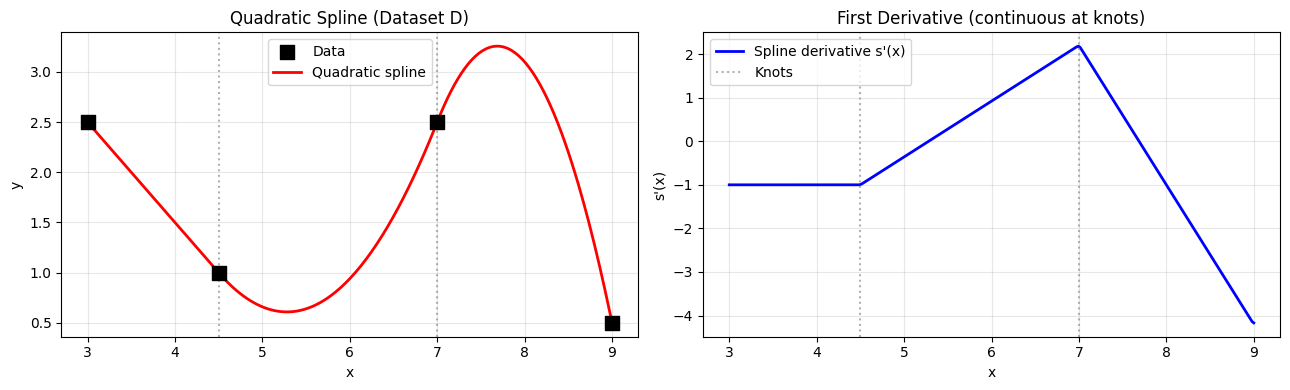

In [14]:
# Apply to Dataset D
b_qs, c_qs = quadratic_spline(x_sp, y_sp)
print('Quadratic spline coefficients (Dataset D):')
for i in range(len(b_qs)):
    print(f'  Interval [{x_sp[i]:.1f}, {x_sp[i+1]:.1f}]:  b={b_qs[i]:.5f},  c={c_qs[i]:.5f}')

# Evaluate at x = 5.0
y_at5 = eval_quadratic_spline(x_sp, y_sp, b_qs, c_qs, 5.0)
print(f'\nInterpolated value at x=5: {y_at5[0]:.5f}  (textbook: 0.66)')

xx_sp = np.linspace(x_sp[0], x_sp[-1], 300)
yy_qs = eval_quadratic_spline(x_sp, y_sp, b_qs, c_qs, xx_sp)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.scatter(x_sp, y_sp, c='k', marker='s', s=100, zorder=5, label='Data')
ax.plot(xx_sp, yy_qs, 'r-', lw=2, label='Quadratic spline')
for xi in x_sp[1:-1]:
    ax.axvline(xi, color='gray', ls=':', alpha=0.6)
ax.set(xlabel='x', ylabel='y', title='Quadratic Spline (Dataset D)')
ax.legend(); ax.grid(True, alpha=0.3)

# Check derivative continuity
ax = axes[1]
deriv = np.gradient(yy_qs, xx_sp)
ax.plot(xx_sp, deriv, 'b-', lw=2, label="Spline derivative s'(x)")
for xi in x_sp[1:-1]:
    ax.axvline(xi, color='gray', ls=':', alpha=0.6, label='Knots' if xi == x_sp[1] else '')
ax.set(xlabel='x', ylabel="s'(x)", title="First Derivative (continuous at knots)")
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

---
## 6. Cubic Splines

### 6.1 Why Cubic?

Quadratic splines have continuous first derivatives but **discontinuous second derivatives** — visible as kinks in curvature. Cubic splines add:
- **Second-derivative continuity** at interior knots: $s_i''(x_{i+1}) = s_{i+1}''(x_{i+1})$

Each cubic segment:
$$s_i(x) = y_i + b_i(x-x_i) + c_i(x-x_i)^2 + d_i(x-x_i)^3$$

### 6.2 Solving for the Second-Derivative Moments

Let $M_i = s_i''(x_i)$ (the "moments"). For $n$ data points, the $M_i$ satisfy a **tridiagonal system**:

$$h_{i-1} M_{i-1} + 2(h_{i-1} + h_i) M_i + h_i M_{i+1}
= 6\left(\frac{y_{i+1} - y_i}{h_i} - \frac{y_i - y_{i-1}}{h_{i-1}}\right)$$

where $h_i = x_{i+1} - x_i$.

### 6.3 Boundary Conditions

| Condition | Equations | When to use |
|-----------|-----------|-------------|
| **Natural** | $M_0 = 0$, $M_{n-1} = 0$ | Unknown end slopes |
| **Not-a-knot** | $d_0 = d_1$, $d_{n-2} = d_{n-3}$ | No info about end behavior |

In [15]:
def cubic_spline_natural(x, y):
    """
    Compute natural cubic spline coefficients.
    Boundary condition: M[0] = M[n-1] = 0  (zero second derivative at endpoints).

    Each segment: s_i(t) = y[i] + b[i]*(t-x[i]) + c[i]*(t-x[i])^2 + d[i]*(t-x[i])^3
    where c[i] = M[i]/2  and  d[i] = (M[i+1]-M[i])/(6*h[i])

    Parameters
    ----------
    x, y : array of length n

    Returns
    -------
    b, c, d : arrays of length n-1
    """
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    n = len(x)
    h = x[1:] - x[:-1]                # h[i] = x[i+1] - x[i]

    # Right-hand side for interior nodes i = 1, ..., n-2
    rhs = np.zeros(n)
    for i in range(1, n-1):
        rhs[i] = 6.0 * ((y[i+1]-y[i])/h[i] - (y[i]-y[i-1])/h[i-1])

    # Build tridiagonal system  A * M = rhs
    A = np.zeros((n, n))
    A[0, 0] = 1.0                      # Natural BC: M[0] = 0
    A[n-1, n-1] = 1.0                  # Natural BC: M[n-1] = 0
    for i in range(1, n-1):
        A[i, i-1] = h[i-1]
        A[i, i]   = 2.0 * (h[i-1] + h[i])
        A[i, i+1] = h[i]

    M = np.linalg.solve(A, rhs)        # second derivatives at knots

    # Recover spline coefficients
    c = M[:-1] / 2.0                   # c[i] = M[i] / 2
    d = (M[1:] - M[:-1]) / (6.0 * h)  # d[i] = (M[i+1]-M[i]) / (6*h[i])
    b = (y[1:] - y[:-1])/h - h*(2*M[:-1] + M[1:])/6.0   # slope at left knot

    return b, c, d, M


def eval_cubic_spline(x, y, b, c, d, xx):
    """Evaluate the cubic spline at points xx."""
    xx  = np.atleast_1d(np.array(xx, dtype=float))
    yy  = np.empty(xx.shape)
    for k, xk in enumerate(xx):
        i  = np.searchsorted(x, xk, side='right') - 1
        i  = np.clip(i, 0, len(x) - 2)
        dx = xk - x[i]
        yy[k] = y[i] + b[i]*dx + c[i]*dx**2 + d[i]*dx**3
    return yy

<!-- SOLUTION
rhs[i] = 6.0 * ((y[i+1]-y[i])/h[i] - (y[i]-y[i-1])/h[i-1])
-->

Cubic spline moments M (second derivatives at knots):
  M[0] = 0.000000
  M[1] = 1.679087
  M[2] = -1.533080
  M[3] = 0.000000

Cubic spline coefficients:
  Interval [3.0, 4.5]:
    b=-1.41977, c=0.00000, d=0.18657
  Interval [4.5, 7.0]:
    b=-0.16046, c=0.83954, d=-0.21414
  Interval [7.0, 9.0]:
    b=0.02205, c=-0.76654, d=0.12776

At x=5:  Cubic spline = 1.102890  (textbook: 1.1029)
At x=5:  Quadratic    = 0.660000


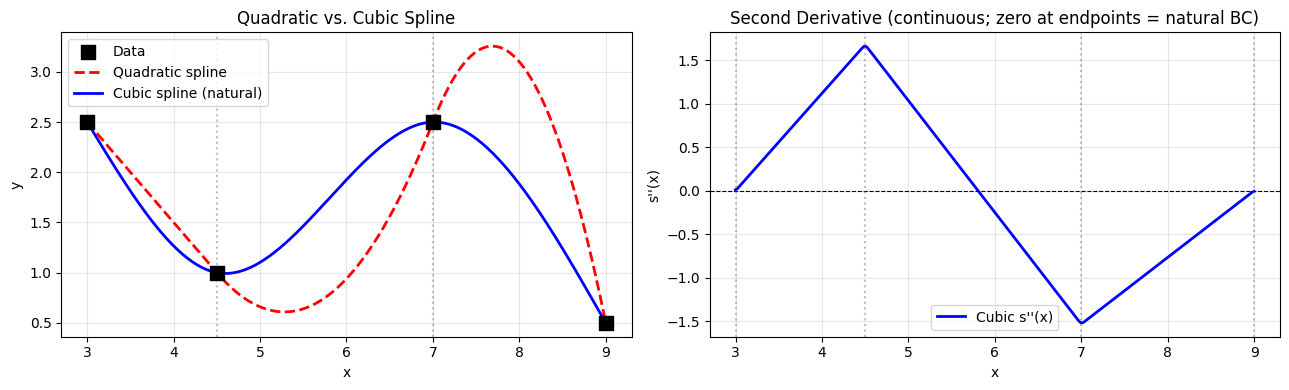

In [16]:
# Apply natural cubic spline to Dataset D
b_cs, c_cs, d_cs, M_cs = cubic_spline_natural(x_sp, y_sp)

print('Cubic spline moments M (second derivatives at knots):')
for i, Mi in enumerate(M_cs):
    print(f'  M[{i}] = {Mi:.6f}')
print()
print('Cubic spline coefficients:')
for i in range(len(b_cs)):
    print(f'  Interval [{x_sp[i]:.1f}, {x_sp[i+1]:.1f}]:')
    print(f'    b={b_cs[i]:.5f}, c={c_cs[i]:.5f}, d={d_cs[i]:.5f}')

y_cs_at5 = eval_cubic_spline(x_sp, y_sp, b_cs, c_cs, d_cs, 5.0)
y_qs_at5 = eval_quadratic_spline(x_sp, y_sp, b_qs, c_qs, 5.0)
print(f'\nAt x=5:  Cubic spline = {y_cs_at5[0]:.6f}  (textbook: 1.1029)')
print(f'At x=5:  Quadratic    = {y_qs_at5[0]:.6f}')

yy_cs = eval_cubic_spline(x_sp, y_sp, b_cs, c_cs, d_cs, xx_sp)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.scatter(x_sp, y_sp, c='k', marker='s', s=100, zorder=5, label='Data')
ax.plot(xx_sp, yy_qs, 'r--', lw=2, label='Quadratic spline')
ax.plot(xx_sp, yy_cs, 'b-',  lw=2, label='Cubic spline (natural)')
for xi in x_sp[1:-1]:
    ax.axvline(xi, color='gray', ls=':', alpha=0.5)
ax.set(xlabel='x', ylabel='y', title='Quadratic vs. Cubic Spline')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
deriv_cs = np.gradient(yy_cs, xx_sp)
deriv2_cs = np.gradient(deriv_cs, xx_sp)
ax.plot(xx_sp, deriv2_cs, 'b-', lw=2, label="Cubic s''(x)")
ax.axhline(0, color='k', lw=0.8, ls='--')
for xi in x_sp:
    ax.axvline(xi, color='gray', ls=':', alpha=0.5)
ax.set(xlabel='x', ylabel="s''(x)",
       title="Second Derivative (continuous; zero at endpoints = natural BC)")
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

### 6.3 Spline vs. High-Degree Polynomial: Runge's Function

Let's compare how a natural cubic spline handles Runge's function compared to a high-degree polynomial.

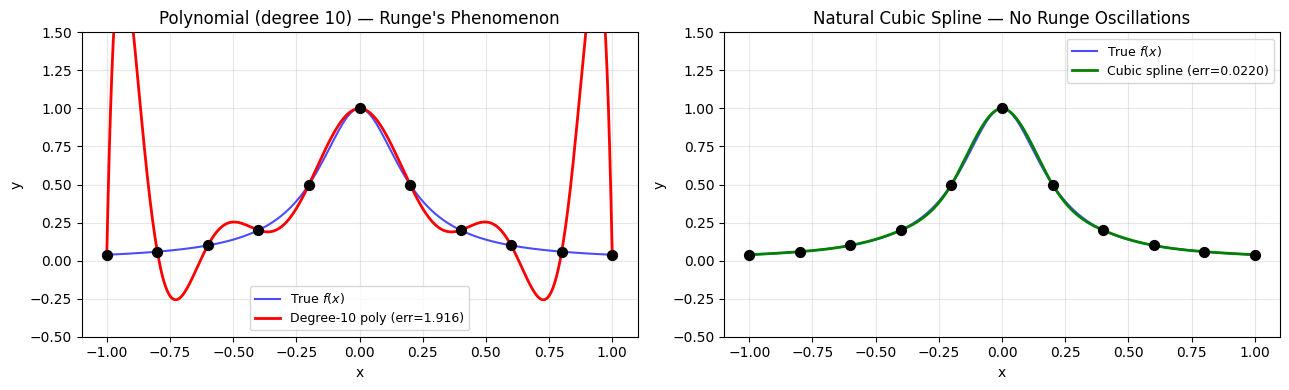

Max error — Polynomial : 1.9156
Max error — Cubic spline: 0.0220
Spline is 87.2x more accurate on this example!


In [17]:
# Runge's function: compare polynomial (degree 10) vs. cubic spline (11 nodes)
n_nodes = 11
x_nodes = np.linspace(-1, 1, n_nodes)
y_nodes = f_runge(x_nodes)

# High-degree polynomial via Newton
b_poly = newtdd_table(x_nodes, y_nodes)
y_poly = newtdd_eval(x_nodes, b_poly, x_dense)

# Natural cubic spline
b_sp, c_sp, d_sp, _ = cubic_spline_natural(x_nodes, y_nodes)
y_csp = eval_cubic_spline(x_nodes, y_nodes, b_sp, c_sp, d_sp, x_dense)

err_poly = np.max(np.abs(y_poly - y_true))
err_csp  = np.max(np.abs(y_csp  - y_true))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(x_dense, y_true, 'b-', lw=1.5, alpha=0.7, label='True $f(x)$')
ax.plot(x_dense, y_poly, 'r-', lw=2,   label=f'Degree-10 poly (err={err_poly:.3f})')
ax.scatter(x_nodes, y_nodes, c='k', s=50, zorder=5)
ax.set(xlabel='x', ylabel='y', title="Polynomial (degree 10) — Runge's Phenomenon",
       ylim=[-0.5, 1.5])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(x_dense, y_true, 'b-', lw=1.5, alpha=0.7, label='True $f(x)$')
ax.plot(x_dense, y_csp,  'g-', lw=2,   label=f'Cubic spline (err={err_csp:.4f})')
ax.scatter(x_nodes, y_nodes, c='k', s=50, zorder=5)
ax.set(xlabel='x', ylabel='y', title='Natural Cubic Spline — No Runge Oscillations',
       ylim=[-0.5, 1.5])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print(f'Max error — Polynomial : {err_poly:.4f}')
print(f'Max error — Cubic spline: {err_csp:.4f}')
print(f'Spline is {err_poly/err_csp:.1f}x more accurate on this example!')

---
## 7. `scipy.interpolate.CubicSpline`

In practice, use `scipy`'s optimized and well-tested implementation.

### 7.1 API

```python
from scipy.interpolate import CubicSpline

cs = CubicSpline(x, y, bc_type='natural')   # or 'not-a-knot'
y_interp = cs(xx)          # evaluate at new points
dy_dx    = cs(xx, 1)       # first derivative
d2y_dx2  = cs(xx, 2)       # second derivative
```

| `bc_type` | Description |
|-----------|-------------|
| `'natural'` | $s''(x_0) = s''(x_{n-1}) = 0$ |
| `'not-a-knot'` | $d_0 = d_1$ and $d_{n-2} = d_{n-3}$ (default) |
| `'clamped'` | Specify end slopes: `bc_type=((1, f'(x0)), (1, f'(xn)))` |

Comparison at x=5.0:
  Our natural spline : 1.10288973
  scipy natural      : 1.10288973
  scipy not-a-knot   : 1.15185185


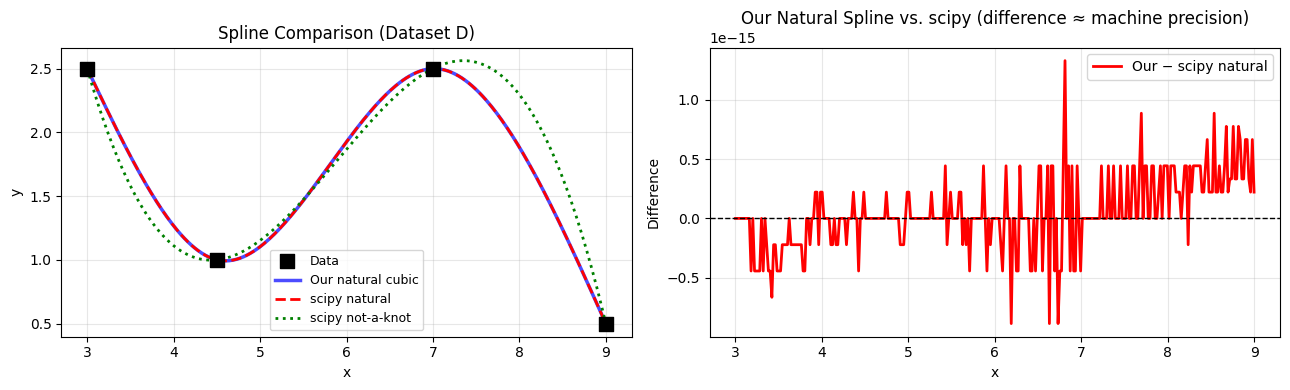

In [18]:
# Compare our implementation vs. scipy on Dataset D
cs_nat = CubicSpline(x_sp, y_sp, bc_type='natural')
cs_nak = CubicSpline(x_sp, y_sp, bc_type='not-a-knot')

y_scipy_nat = cs_nat(xx_sp)
y_scipy_nak = cs_nak(xx_sp)

print('Comparison at x=5.0:')
print(f'  Our natural spline : {eval_cubic_spline(x_sp, y_sp, b_cs, c_cs, d_cs, 5.0)[0]:.8f}')
print(f'  scipy natural      : {cs_nat(5.0):.8f}')
print(f'  scipy not-a-knot   : {cs_nak(5.0):.8f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.scatter(x_sp, y_sp, c='k', marker='s', s=100, zorder=5, label='Data')
ax.plot(xx_sp, yy_cs,       'b-',  lw=2.5, label='Our natural cubic', alpha=0.7)
ax.plot(xx_sp, y_scipy_nat, 'r--', lw=2,   label='scipy natural')
ax.plot(xx_sp, y_scipy_nak, 'g:',  lw=2,   label='scipy not-a-knot')
ax.set(xlabel='x', ylabel='y', title='Spline Comparison (Dataset D)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(xx_sp, yy_cs - y_scipy_nat, 'r-', lw=2, label='Our − scipy natural')
ax.axhline(0, color='k', lw=1, ls='--')
ax.set(xlabel='x', ylabel='Difference',
       title='Our Natural Spline vs. scipy (difference ≈ machine precision)')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

### 7.2 Application: Runge's Function (scipy)

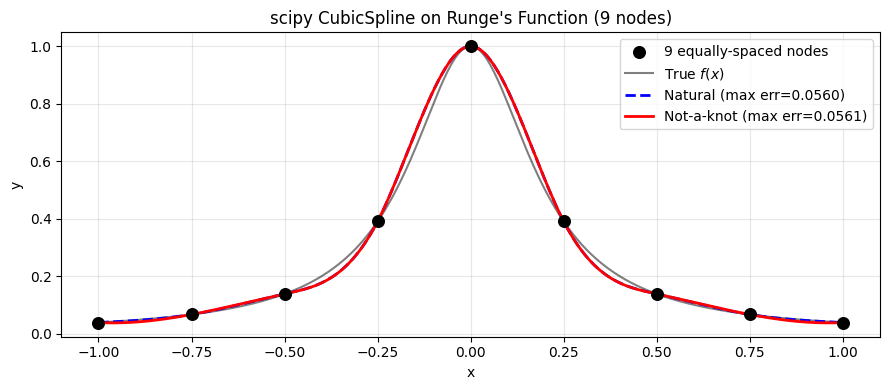

In [19]:
# Runge's function: compare 'natural' vs. 'not-a-knot'
x_runge9 = np.linspace(-1, 1, 9)
y_runge9 = f_runge(x_runge9)

cs_nat_r = CubicSpline(x_runge9, y_runge9, bc_type='natural')
cs_nak_r = CubicSpline(x_runge9, y_runge9, bc_type='not-a-knot')

y_nat_r = cs_nat_r(x_dense)
y_nak_r = cs_nak_r(x_dense)

err_nat = np.max(np.abs(y_nat_r - y_true))
err_nak = np.max(np.abs(y_nak_r - y_true))

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(x_runge9, y_runge9, c='k', marker='o', s=70, zorder=5, label='9 equally-spaced nodes')
ax.plot(x_dense, y_true,  'k-',  lw=1.5, alpha=0.5, label='True $f(x)$')
ax.plot(x_dense, y_nat_r, 'b--', lw=2,   label=f'Natural (max err={err_nat:.4f})')
ax.plot(x_dense, y_nak_r, 'r-',  lw=2,   label=f'Not-a-knot (max err={err_nak:.4f})')
ax.set(xlabel='x', ylabel='y', title="scipy CubicSpline on Runge's Function (9 nodes)")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### 7.3 Derivatives and Integration

∫ rho dT from 300 to 500 K = 105.862500 kg·K/m³


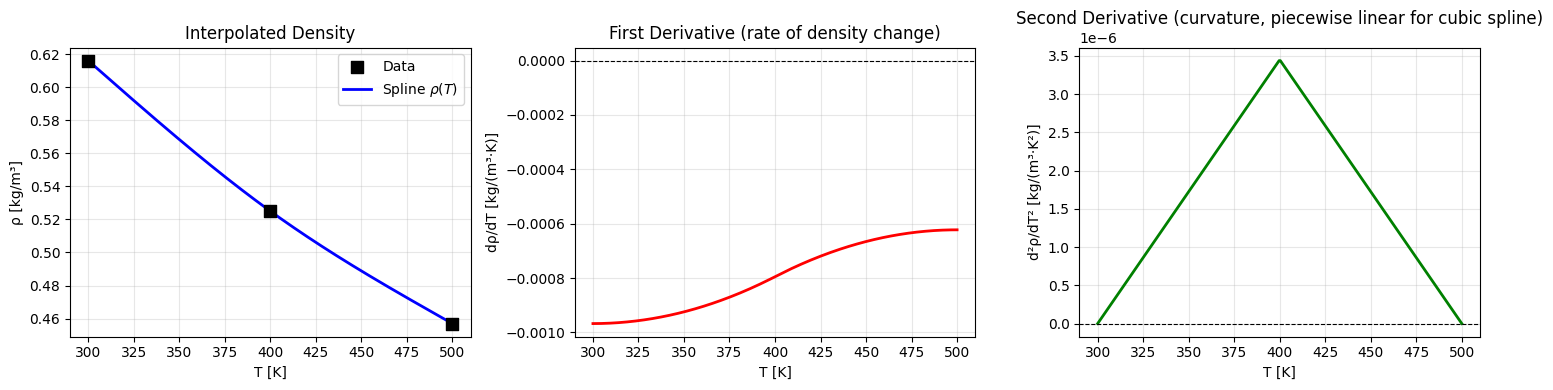

In [20]:
# CubicSpline can compute derivatives and definite integrals
cs_air = CubicSpline(T_air, rho_air, bc_type='natural')
T_fine = np.linspace(300, 500, 300)

rho_fine   = cs_air(T_fine)          # interpolated values
drho_dT    = cs_air(T_fine, 1)       # first derivative  drho/dT
d2rho_dT2  = cs_air(T_fine, 2)       # second derivative d^2rho/dT^2

# Definite integral (antiderivative evaluated at endpoints)
integral = cs_air.integrate(300, 500)
print(f'∫ rho dT from 300 to 500 K = {integral:.6f} kg·K/m³')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.scatter(T_air, rho_air, c='k', marker='s', s=80, zorder=5, label='Data')
ax.plot(T_fine, rho_fine, 'b-', lw=2, label='Spline $\\rho(T)$')
ax.set(xlabel='T [K]', ylabel='ρ [kg/m³]', title='Interpolated Density')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(T_fine, drho_dT, 'r-', lw=2)
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.set(xlabel='T [K]', ylabel='dρ/dT [kg/(m³·K)]',
       title='First Derivative (rate of density change)')
ax.grid(True, alpha=0.3)

ax = axes[2]
ax.plot(T_fine, d2rho_dT2, 'g-', lw=2)
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.set(xlabel='T [K]', ylabel='d²ρ/dT² [kg/(m³·K²)]',
       title='Second Derivative (curvature, piecewise linear for cubic spline)')
ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

### 7.4 Engineering Application: Cam Profile

A cam's lift (displacement) is measured at several rotation angles. We need a smooth profile — and its derivatives (velocity and acceleration) — to design the cam mechanism.

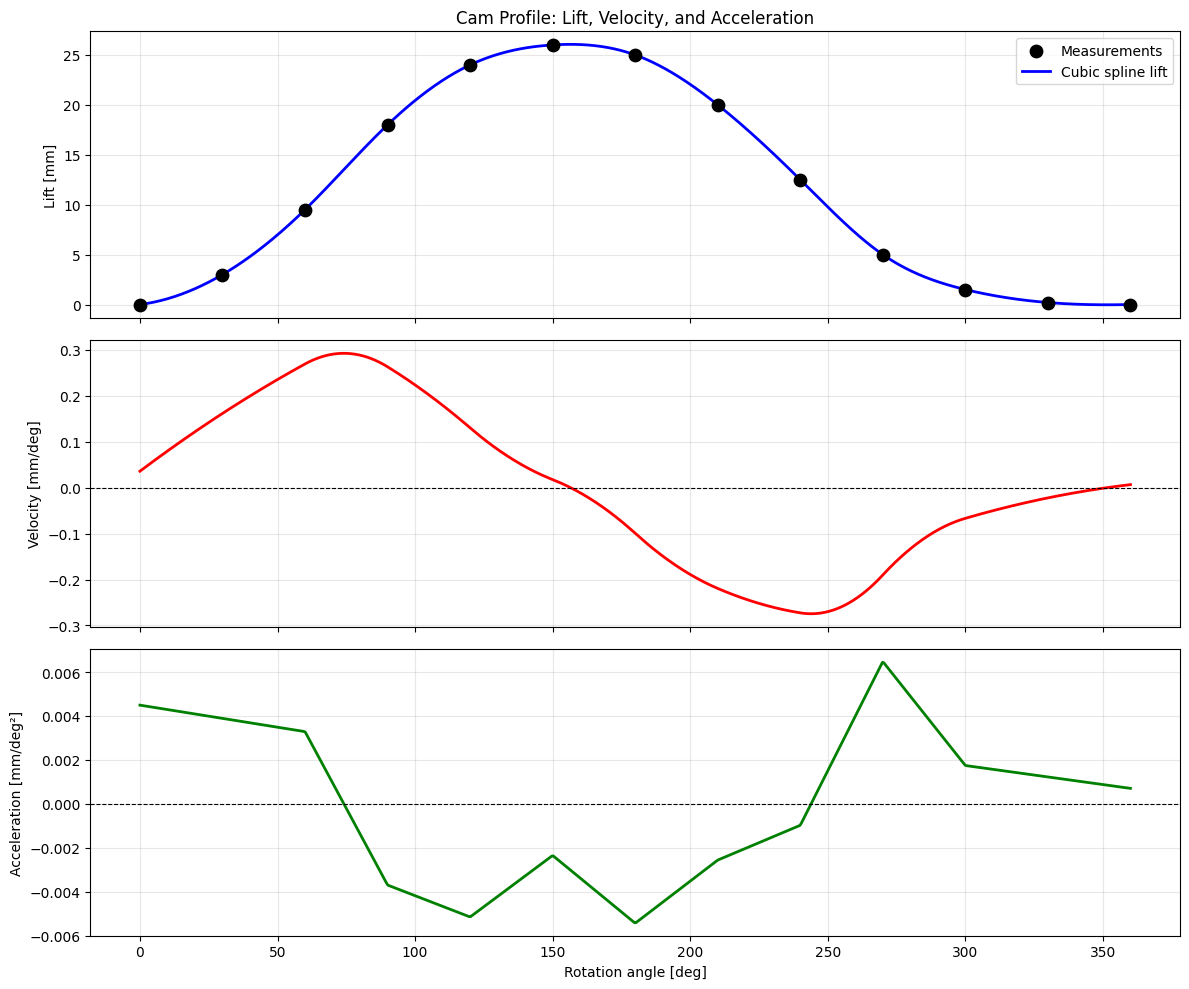

Maximum lift: 26.058 mm at theta = 156.7°
Max |velocity|: 0.2922 mm/deg at theta = 74.1°


In [21]:
# Cam profile: lift y [mm] vs. rotation angle theta [degrees]
theta_data = np.array([0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360],
                      dtype=float)
lift_data  = np.array([0, 3.0, 9.5, 18.0, 24.0, 26.0, 25.0,
                       20.0, 12.5, 5.0, 1.5, 0.2, 0.0])

# Fit not-a-knot cubic spline (periodic data -> use 'periodic' or 'not-a-knot')
cs_cam = CubicSpline(theta_data, lift_data, bc_type='not-a-knot')

theta_fine = np.linspace(0, 360, 720)
lift_fine  = cs_cam(theta_fine)          # y  [mm]
vel_fine   = cs_cam(theta_fine, 1)       # dy/dtheta  [mm/deg]
acc_fine   = cs_cam(theta_fine, 2)       # d²y/dtheta²  [mm/deg²]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

ax = axes[0]
ax.scatter(theta_data, lift_data, c='k', marker='o', s=80, zorder=5, label='Measurements')
ax.plot(theta_fine, lift_fine, 'b-', lw=2, label='Cubic spline lift')
ax.set(ylabel='Lift [mm]', title='Cam Profile: Lift, Velocity, and Acceleration')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(theta_fine, vel_fine, 'r-', lw=2)
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.set(ylabel='Velocity [mm/deg]')
ax.grid(True, alpha=0.3)

ax = axes[2]
ax.plot(theta_fine, acc_fine, 'g-', lw=2)
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.set(xlabel='Rotation angle [deg]', ylabel='Acceleration [mm/deg²]')
ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

idx_max = np.argmax(lift_fine)
print(f'Maximum lift: {lift_fine[idx_max]:.3f} mm at theta = {theta_fine[idx_max]:.1f}°')
idx_maxv = np.argmax(np.abs(vel_fine))
print(f'Max |velocity|: {np.abs(vel_fine[idx_maxv]):.4f} mm/deg at theta = {theta_fine[idx_maxv]:.1f}°')

---
## Summary

### Methods Overview

| Method | Degree | Smooth? | Best when |
|--------|--------|---------|----------|
| **Newton / Lagrange** | $n$ (global) | $C^\infty$ | Few points, need exact polynomial form |
| **Quadratic spline** | 2 (piecewise) | $C^1$ | Fast, simple, continuous slope |
| **Cubic spline (natural)** | 3 (piecewise) | $C^2$ | Most engineering problems, unknown end slopes |
| **Cubic spline (not-a-knot)** | 3 (piecewise) | $C^2$ | Default scipy choice, smooth extrapolation |
| **High-degree polynomial** | $n$ | $C^\infty$ | Chebyshev nodes only; avoid equally-spaced! |

### Key Formulas

| Concept | Formula |
|---------|--------|
| Newton's polynomial | $p_n(x) = \sum_{k=0}^n b_k \prod_{j=0}^{k-1}(x - x_j)$ |
| Divided difference | $f[x_i,\ldots,x_{i+k}] = \dfrac{f[x_{i+1},\ldots,x_{i+k}] - f[x_i,\ldots,x_{i+k-1}]}{x_{i+k} - x_i}$ |
| Lagrange polynomial | $p_n(x) = \sum_i y_i L_i(x)$, $\quad L_i(x) = \prod_{j\neq i}\dfrac{x-x_j}{x_i-x_j}$ |
| Cubic spline segment | $s_i(x) = y_i + b_i(x-x_i) + c_i(x-x_i)^2 + d_i(x-x_i)^3$ |
| Cubic spline moments | $h_{i-1}M_{i-1} + 2(h_{i-1}+h_i)M_i + h_iM_{i+1} = 6\left(\frac{\Delta y_i}{h_i} - \frac{\Delta y_{i-1}}{h_{i-1}}\right)$ |
| Chebyshev nodes | $x_k = \cos\!\left(\frac{(2k+1)\pi}{2(n+1)}\right)$, $\;k=0,\ldots,n$ |

### Decision Guide

```
Do you have exact data (no noise)?
  YES -> Interpolation
    How many data points n?
      n <= 4 and accuracy is critical:
        -> Newton / Lagrange (global polynomial)
           But check: equally spaced? if n > 6, consider Chebyshev nodes or spline
      n > 4 or smooth curve needed:
        -> Cubic spline (scipy CubicSpline)
           bc_type='not-a-knot'  : default, good for general data
           bc_type='natural'     : when endpoints should have zero curvature
  NO  -> Regression (see Lab09)
```

### Engineering Applications

| Application | Data | Method |
|-------------|------|--------|
| Tabulated material property (density vs. T) | Exact table | Newton or cubic spline |
| Cam profile design | Measured lift angles | `CubicSpline` + derivatives |
| Rocket trajectory | Discrete altitude measurements | `CubicSpline` |
| Digital terrain model | Elevation at scattered points | Spline interpolation |
| Signal reconstruction | Band-limited samples | Spline or DFT (Lab10) |